In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import mean_absolute_error, r2_score, accuracy_score, confusion_matrix
import plotly.express as px

df = pd.read_excel("week10_students lab 5.xlsx")
df.head()



,student_id,name,gender,program,district,attendance_pct,quiz_avg,assignments_avg,score
0,AUCA001,Aline Uwase,F,Information Systems,Gasabo,55,31.0,35.0,28.6
1,AUCA002,Eric Iradukunda,M,Software Engineering,Musanze,73,61.1,76.7,64.5
2,AUCA003,Diane Uwizeyimana,F,Networking,Muhanga,92,35.2,65.5,52.7
3,AUCA004,Jean Bosco Ikirezi,M,Accounting,Kicukiro,69,65.2,54.2,68.3
4,AUCA005,Patrick Ingabire,M,Information Systems,Huye,88,39.3,42.9,42.3


In [3]:
print(df.shape)
print(df[["quiz_avg", "assignments_avg", "attendance_pct", "score"]].corr()["score"])


(150, 9)
quiz_avg           0.800726
assignments_avg    0.535983
attendance_pct     0.238118
score              1.000000
Name: score, dtype: float64


In [4]:
features = ["quiz_avg", "assignments_avg", "attendance_pct"]
X = df[features]
y = df["score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42)
print(len(X_train), len(X_test))

112 38


In [ ]:
# Comment: why hide 25%?
new, unseen students” so you can test whether the model truly generalises rather than just memorising the data it trained on.

In [ ]:
Part 2: Regression
2.1 train and read the model

In [5]:
model = LinearRegression().fit(X_train, y_train)
for name, coef in zip(features, model.coef_):
    print(f"{name}: {coef:.3f}")
print("Intercept:", model.intercept_)

quiz_avg: 0.579
assignments_avg: 0.365
attendance_pct: 0.113
Intercept: -4.4282133361542435


In [6]:
pred = model.predict(X_test)          
print("MAE:", mean_absolute_error(y_test, pred))   
print("R2:", r2_score(y_test, pred))               

MAE: 3.3291993077316526
R2: 0.886648735661214


In [ ]:
# 
MAE: on average, predictions are off by about 3.3 points.
R²: the three features explain about 89% of the differences in scores between students.

In [7]:
# 2.3 predict a new student
new = pd.DataFrame({"quiz_avg": [70], "assignments_avg": [75], "attendance_pct": [90]})
print(model.predict(new))

mine = pd.DataFrame({"quiz_avg": [60], "assignments_avg": [65], "attendance_pct": [85]}) 

[73.66410989]


In [8]:
# Part 3.  Classification
# 3.1 build the target and train
df["passed"] = (df["score"] >= 50).astype(int)
print(df["passed"].value_counts())

yc = df["passed"]
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X, yc, test_size=0.25, random_state=42)
clf = LogisticRegression(max_iter=1000).fit(Xc_train, yc_train)

passed
1    131
0     19
Name: count, dtype: int64


In [9]:
# 3.2 The accuracy trap
cpred = clf.predict(Xc_test)
print("Model accuracy:", accuracy_score(yc_test, cpred))
print("Lazy baseline:", yc_test.mean())        # "predict pass for everyone"
print(confusion_matrix(yc_test, cpred))

Model accuracy: 0.8947368421052632
Lazy baseline: 0.8947368421052632
[[ 3  1]
 [ 3 31]]


In [ ]:
#The matrix is laid out as [[TN, FP], [FN, TP]], with “fail” as class 0. 
#The point of the trap is that the lazy baseline gets zero of the failing students right, while your model correctly catches some of them (look at the top-left number).
#Accuracy hides this because most students pass. The model is not useless: it finds at-risk students, which is the whole purpose. Use your actual numbers in the argument

In [10]:
# Part 4: feature engineering
def eval_r2(X_):
    Xtr, Xte, ytr, yte = train_test_split(X_, y, test_size=0.25, random_state=42)
    m = LinearRegression().fit(Xtr, ytr)
    return r2_score(yte, m.predict(Xte))

r2_quiz = eval_r2(df[["quiz_avg"]])
r2_three = eval_r2(df[features])
X_prog = pd.get_dummies(df[features + ["program"]], columns=["program"], drop_first=True)
r2_prog = eval_r2(X_prog)

print(pd.DataFrame({"Model": ["quiz only", "3 numeric", "3 numeric + program"],
                    "Test R2": [r2_quiz, r2_three, r2_prog]}))

                 Model   Test R2
0            quiz only  0.624162
1            3 numeric  0.886649
2  3 numeric + program  0.880435


In [ ]:
#adding the two other numeric features helped a lot, while adding program did not help (it was slightly lower). The lesson is that more information is not automatically better: useful features help, and irrelevant ones add noise.

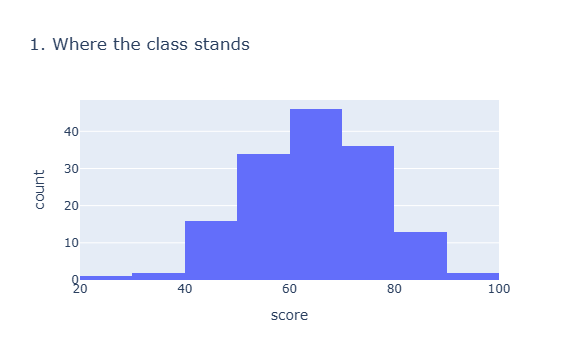

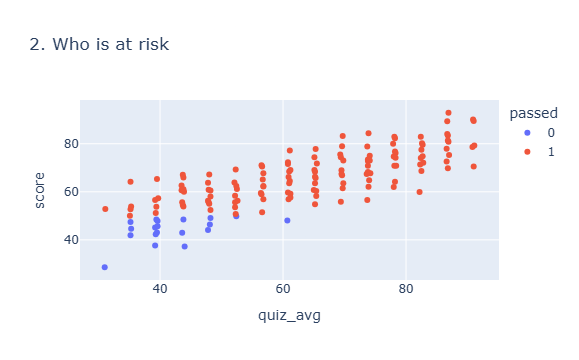

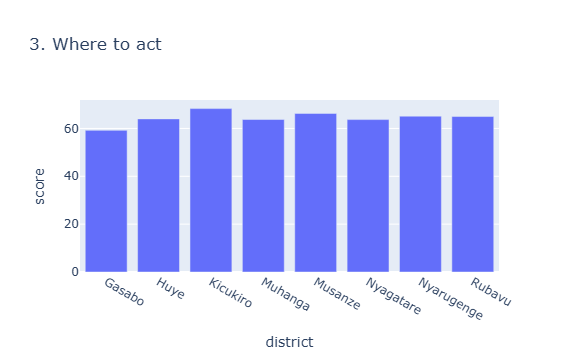

In [11]:
# Part 5: Dashboard
fig1 = px.histogram(df, x="score", nbins=12, title="1. Where the class stands")
fig1.show()

df["passed"] = df["passed"].astype(str)  
fig2 = px.scatter(df, x="quiz_avg", y="score", color="passed",
                  hover_name="name", title="2. Who is at risk")
fig2.show()

district_avg = df.groupby("district", as_index=False)["score"].mean()
fig3 = px.bar(district_avg, x="district", y="score", title="3. Where to act")
fig3.show()

In [12]:
fig2.write_html("class_dashboard.html")

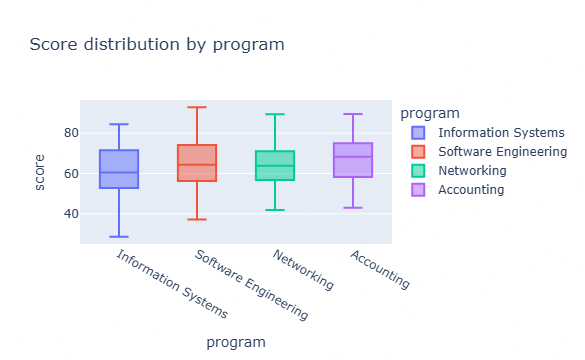

In [13]:
px.box(df, x="program", y="score", color="program", title="Score distribution by program").show()

Part 6: Model card (required)

Write four short sections in a markdown cell or Word document:

1.Purpose: predicts a student’s final score from quiz average, assignment     average and attendance, for AUCA instructors or advisors.
2.Data and features: 150 clean student records; three numeric features; target is score.
3.Performance: on 38 unseen students, predictions are typically about 3.3 points off (MAE), and the model explains about 89% of score variation (R²).
4.Risks: a wrong prediction could unfairly label a student as failing or hide a struggling one. Use it as an early-warning aid to start supportive conversations. Do not use it to grade, penalise or exclude students. It was trained on only 150 students, so treat it with caution.